# Tensor Train Representation of the Burgers Equation Solution

## Objective

In this notebook, the classical Burgers equation solution obtained
from Notebook 1 is represented using a Tensor Train (TT) format.

The TT representation is reconstructed and compared with the original
classical solution using the relative L2 error.

The effect of the TT bond dimension on reconstruction accuracy is
also investigated.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = np.load("../results/data/burgers_classical_data.npz")

x = data["x"]
times = data["times"]
solutions = data["solutions"]

print("x shape:", x.shape)
print("times:", times)
print("solutions shape:", solutions.shape)

x shape: (8,)
times: [0.  0.1 0.2 0.3 0.4 0.5]
solutions shape: (6, 8)


In [3]:
u = solutions[-1]

print("Time:", times[-1])
print("u:")
print(u)

Time: 0.5
u:
[0.00000000e+00 1.57767192e-01 3.10550179e-01 4.50815488e-01
 5.62318168e-01 6.00812330e-01 4.50918434e-01 1.22464680e-16]


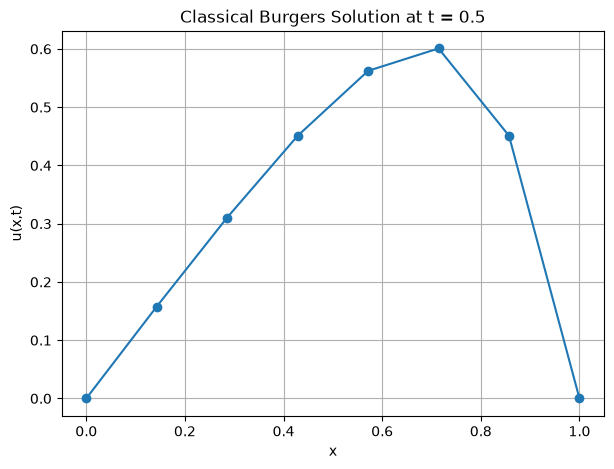

In [4]:
plt.figure(figsize=(7,5))

plt.plot(x, u, 'o-')

plt.xlabel("x")
plt.ylabel("u(x,t)")
plt.title(f"Classical Burgers Solution at t = {times[-1]:.1f}")
plt.grid(True)

plt.show()

In [5]:
u_tensor = u.reshape(2, 2, 2)

print("Original vector shape:", u.shape)
print("Tensor shape:", u_tensor.shape)

Original vector shape: (8,)
Tensor shape: (2, 2, 2)


In [6]:
def tt_svd(tensor, max_rank=None, tolerance=1e-12):

    shape = tensor.shape
    d = len(shape)

    cores = []
    ranks = [1]

    current = tensor.copy()

    for k in range(d - 1):

        r_prev = ranks[-1]
        n_k = shape[k]

        # Reshape tensor into a matrix
        current = current.reshape(
            r_prev * n_k,
            -1
        )

        # Singular Value Decomposition
        U, S, Vt = np.linalg.svd(
            current,
            full_matrices=False
        )

        # Determine rank
        if max_rank is not None:
            rank = min(max_rank, len(S))
        else:
            rank = len(S)

        # Truncate
        U = U[:, :rank]
        S = S[:rank]
        Vt = Vt[:rank, :]

        # Create TT core
        core = U.reshape(
            r_prev,
            n_k,
            rank
        )

        cores.append(core)

        # Pass remaining part to next step
        current = np.diag(S) @ Vt

        ranks.append(rank)

    # Final TT core
    final_core = current.reshape(
        ranks[-1],
        shape[-1],
        1
    )

    cores.append(final_core)
    ranks.append(1)

    return cores, ranks

In [7]:
cores, ranks = tt_svd(u_tensor)

print("TT ranks:", ranks)

for i, core in enumerate(cores):
    print(f"Core {i+1} shape:", core.shape)

TT ranks: [1, 2, 2, 1]
Core 1 shape: (1, 2, 2)
Core 2 shape: (2, 2, 2)
Core 3 shape: (2, 2, 1)


In [8]:
def tt_reconstruct(cores):

    result = cores[0]

    for core in cores[1:]:

        result = np.tensordot(
            result,
            core,
            axes=([-1], [0])
        )

    return np.squeeze(result)

In [9]:
u_tensor_reconstructed = tt_reconstruct(cores)

print("Original tensor shape:",
      u_tensor.shape)

print("Reconstructed tensor shape:",
      u_tensor_reconstructed.shape)

Original tensor shape: (2, 2, 2)
Reconstructed tensor shape: (2, 2, 2)


In [10]:
u_tt = u_tensor_reconstructed.reshape(-1)

print("Original:")
print(u)

print("\nTT reconstructed:")
print(u_tt)

Original:
[0.00000000e+00 1.57767192e-01 3.10550179e-01 4.50815488e-01
 5.62318168e-01 6.00812330e-01 4.50918434e-01 1.22464680e-16]

TT reconstructed:
[9.93421868e-17 1.57767192e-01 3.10550179e-01 4.50815488e-01
 5.62318168e-01 6.00812330e-01 4.50918434e-01 2.73700128e-17]


In [11]:
error = (
    np.linalg.norm(u - u_tt)
    /
    np.linalg.norm(u)
)

print("Relative L2 reconstruction error =", error)

Relative L2 reconstruction error = 3.8969111853292715e-16


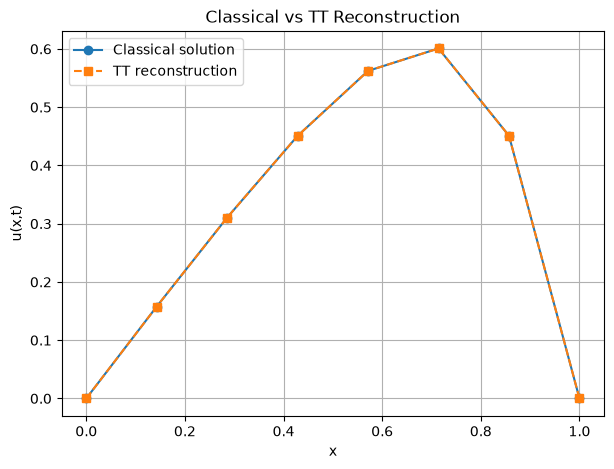

In [12]:
plt.figure(figsize=(7,5))

plt.plot(
    x,
    u,
    'o-',
    label="Classical solution"
)

plt.plot(
    x,
    u_tt,
    's--',
    label="TT reconstruction"
)

plt.xlabel("x")
plt.ylabel("u(x,t)")
plt.title("Classical vs TT Reconstruction")

plt.legend()
plt.grid(True)

plt.show()

In [13]:
chi = 1

cores_1, ranks_1 = tt_svd(
    u_tensor,
    max_rank=chi
)

u_tensor_1 = tt_reconstruct(cores_1)

u_tt_1 = u_tensor_1.reshape(-1)

error_1 = (
    np.linalg.norm(u - u_tt_1)
    /
    np.linalg.norm(u)
)

print("Bond dimension:", chi)
print("Ranks:", ranks_1)
print("Relative L2 error:", error_1)

Bond dimension: 1
Ranks: [1, 1, 1, 1]
Relative L2 error: 0.5039213940319761


In [14]:
chi = 2

cores_2, ranks_2 = tt_svd(
    u_tensor,
    max_rank=chi
)

u_tensor_2 = tt_reconstruct(cores_2)

u_tt_2 = u_tensor_2.reshape(-1)

error_2 = (
    np.linalg.norm(u - u_tt_2)
    /
    np.linalg.norm(u)
)

print("Bond dimension:", chi)
print("Ranks:", ranks_2)
print("Relative L2 error:", error_2)

Bond dimension: 2
Ranks: [1, 2, 2, 1]
Relative L2 error: 3.8969111853292715e-16


In [15]:
bond_dimensions = [1, 2, 3, 4]

errors = []

for chi in bond_dimensions:

    cores, ranks = tt_svd(
        u_tensor,
        max_rank=chi
    )

    reconstructed_tensor = tt_reconstruct(cores)

    reconstructed = reconstructed_tensor.reshape(-1)

    error = (
        np.linalg.norm(u - reconstructed)
        /
        np.linalg.norm(u)
    )

    errors.append(error)

    print(
        f"chi = {chi}, "
        f"ranks = {ranks}, "
        f"error = {error:.6e}"
    )

chi = 1, ranks = [1, 1, 1, 1], error = 5.039214e-01
chi = 2, ranks = [1, 2, 2, 1], error = 3.896911e-16
chi = 3, ranks = [1, 2, 2, 1], error = 3.896911e-16
chi = 4, ranks = [1, 2, 2, 1], error = 3.896911e-16


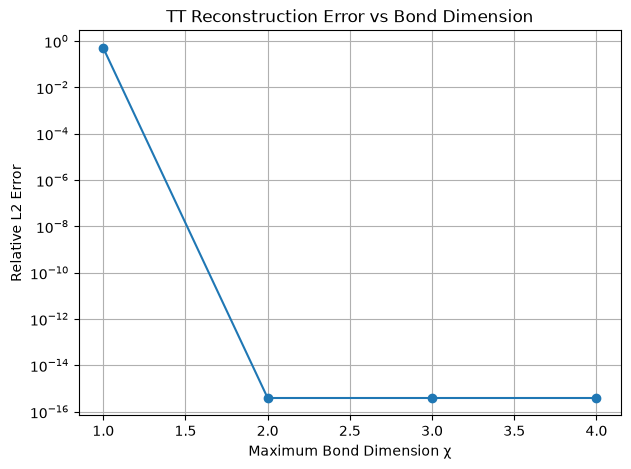

In [16]:
plt.figure(figsize=(7,5))

plt.semilogy(
    bond_dimensions,
    errors,
    'o-'
)

plt.xlabel("Maximum Bond Dimension χ")
plt.ylabel("Relative L2 Error")
plt.title("TT Reconstruction Error vs Bond Dimension")

plt.grid(True)

plt.show()

In [17]:
chi = 1

time_errors = []

for j, t in enumerate(times):

    u_current = solutions[j]

    tensor = u_current.reshape(2, 2, 2)

    cores, ranks = tt_svd(
        tensor,
        max_rank=chi
    )

    reconstructed_tensor = tt_reconstruct(cores)

    reconstructed = reconstructed_tensor.reshape(-1)

    error = (
        np.linalg.norm(u_current - reconstructed)
        /
        np.linalg.norm(u_current)
    )

    time_errors.append(error)

    print(
        f"t = {t:.1f}, "
        f"ranks = {ranks}, "
        f"error = {error:.6e}"
    )

t = 0.0, ranks = [1, 1, 1, 1], error = 5.607498e-01
t = 0.1, ranks = [1, 1, 1, 1], error = 5.421714e-01
t = 0.2, ranks = [1, 1, 1, 1], error = 5.210877e-01
t = 0.3, ranks = [1, 1, 1, 1], error = 5.101448e-01
t = 0.4, ranks = [1, 1, 1, 1], error = 5.054756e-01
t = 0.5, ranks = [1, 1, 1, 1], error = 5.039214e-01


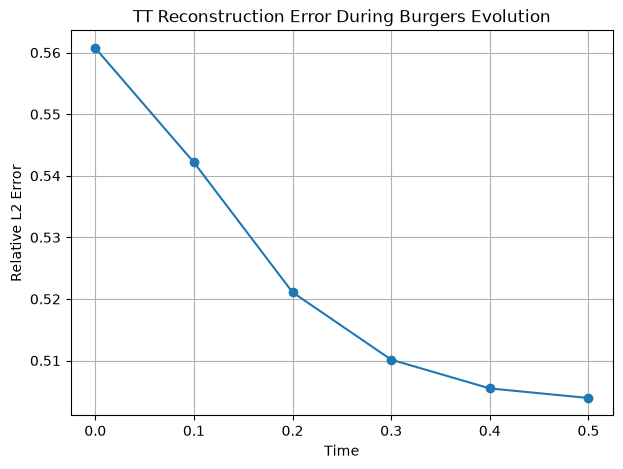

In [18]:
plt.figure(figsize=(7,5))

plt.plot(
    times,
    time_errors,
    'o-'
)

plt.xlabel("Time")
plt.ylabel("Relative L2 Error")
plt.title("TT Reconstruction Error During Burgers Evolution")

plt.grid(True)

plt.show()

In [19]:
np.save(
    "../results/data/tt_bond_dimensions.npy",
    np.array(errors)
)

np.save(
    "../results/data/tt_time_errors.npy",
    np.array(time_errors)
)

np.save(
    "../results/data/tt_bond_dimensions.npy",
    np.array(bond_dimensions)
)